# 라이브러리 임포트
##### 실습에 필요한 라이브러리를 임포트

In [12]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn import set_config
set_config(display="text")

import warnings
warnings.filterwarnings('ignore')

## 데이터 불러오기(학습데이터, 테스트데이터)

In [42]:
# train = pd.read_csv('data/csv/basketball_train.csv')
# test = pd.read_csv('data/csv/basketball_test.csv')

train= pd.read_pickle('data/csv/basketball_train.pkl')
test = pd.read_pickle('data/csv/basketball_test.pkl')

print(train.head())
print(test.head())

             Player Pos   3P  TRB  BLK
26  Wayne Ellington  SG  2.4  2.1  0.1
86     Nik Stauskas  SG  1.7  2.8  0.4
60         Alex Len   C  0.0  6.6  1.3
45      Buddy Hield  SG  1.8  3.3  0.1
68      Jodie Meeks  SG  1.6  2.1  0.1
             Player Pos   3P   TRB  BLK
96      Dwyane Wade  SG  0.8   4.5  0.7
39     Tim Hardaway  SG  1.9   2.8  0.2
21  Jordan Crawford  SG  1.9   1.8  0.1
95   Nikola Vucevic   C  0.3  10.4  1.0
56      Kyle Korver  SG  2.4   2.8  0.3


## SVM 최적의 파라미터 찾기

##### 1. C(cost, 비용) : 결정경계선의 마진을 결정하는 파라미터.
##### 2. gamma : 커널의 데이터포인트 표준 편차를 결정하는 조절 변수

In [18]:
from sklearn.model_selection import GridSearchCV
from sklearn.metrics import classification_report
from sklearn.metrics import accuracy_score
from sklearn.svm import SVC

In [ ]:
# sklearn에서 제공하는 GridSearchCV를 사용하면, 
# 손쉽게 최적의 C, gamma를 구할 수 있음.

def svc_param_selection(x, y, nfolds):
    svc_param = [
        {'kernel' : ['rbf']
        ,'gamma': [0.00001,0.0001, 0.001, 0.01, 0.1, 1]
        ,'C':[0.01, 0.1, 1, 10, 100, 1000]
        }
    ]

    # 현재 학습하는 데이터에 최적의 감마랑 코스트 알기 위해
    clf =  GridSearchCV(SVC(), svc_param, cv=nfolds)
    clf.fit(x,y)
    print(clf.best_params_)

    return clf

In [25]:
x_train = train[['3P', 'BLK']]
y_train = train[['Pos']]

#
clf = svc_param_selection(x_train, y_train, 10)

{'C': 0.1, 'gamma': 1, 'kernel': 'rbf'}


## 시각화
##### 최적의 파라미터일 때의 결정경계선과, 다른 파라미터들일 때의 결정 경계선을 비교.

In [27]:
# 시각화를 하기 위해, 최적의 C와 최적의 C를 비교하기 위한 다른 C를 후보로 저장.
C_candidates = []
C_candidates.append(clf.best_params_['C'] * 0.01)
C_candidates.append(clf.best_params_['C'])
C_candidates.append(clf.best_params_['C'] * 100)

In [ ]:
# 시각화를 하기 위해, 최적의 gamma와 최적의 gamma를 비교하기 위한 다른 C를 후보로 저장.
gamma_candidates = []
gamma_candidates.append(clf.best_params_['gamma'] * 0.01) # 과소 
gamma_candidates.append(clf.best_params_['gamma']) # 적정
gamma_candidates.append(clf.best_params_['gamma'] * 100) # 과대

In [29]:
X = train[['3P', 'BLK']]
Y = train['Pos'].tolist()

In [31]:
# 포지션에 해당하는 문자열 SG와 C를 벡터화합니다.
position = []

for i in Y:
  if i == 'C':
    position.append(0)
  else : # SG
    position.append(1)
        
# 각각의 파라미터에 해당하는 SVM 모델을 만들어 classifiers에 저장.
classifiers = []

for C in C_candidates:
  for gamma in gamma_candidates:
    clf = SVC(C=C, gamma=gamma)
    clf.fit(X, Y)
    classifiers.append((C, gamma, clf))


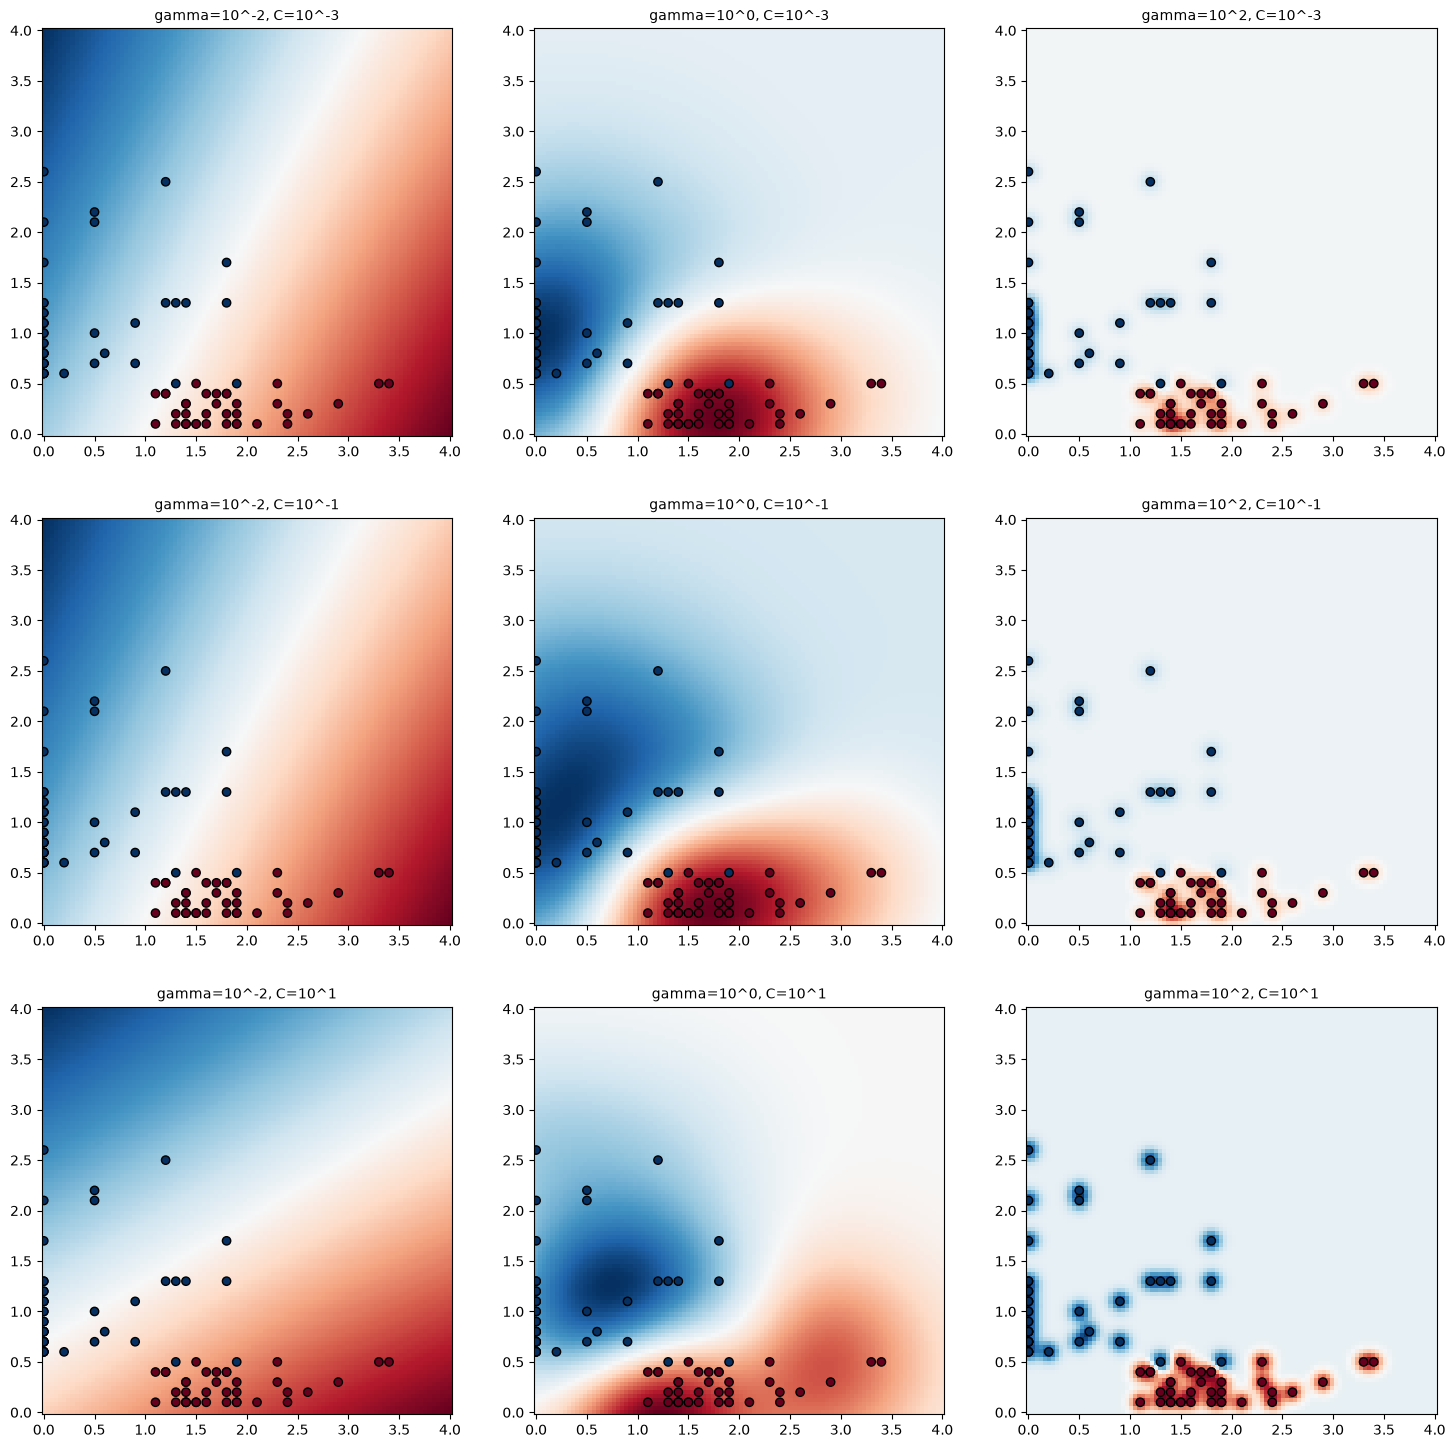

In [65]:
# 18,18 사이즈의 차트를 구성합니다.
plt.figure(figsize=(18, 18)) # 시각화 도화지 크기 설정

# 넘파이 매쉬그리드 => 라인스페이스 x좌표 + y좌표 =(최소영역,최대영역,구간) 
xx, yy = np.meshgrid(np.linspace(0,4,100), np.linspace(0,4,100))

# 각각의 모델들에 대한 결정 경계 함수를 적용하여 함께 시각화합니다.
for (k, (C, gamma, clf)) in enumerate(classifiers):
  Z = clf.decision_function(np.c_[xx.ravel(), yy.ravel()]) # np.c_ : 컬럼열의 뜻 xx + yy
  Z = Z.reshape(xx.shape) # xx목표 모양 확인 -> 2차원 모양 변환

  # 최적의 모델을 포함한 다른 파라미터로 학습된 모델들을 함께 시각화해봅니다.
  # 큰 도화지(Figure)를 여러 개의 작은 칸(서브플롯)으로 쪼개어 그래프를 배치해 주는 기능입니다.
  plt.subplot(len(C_candidates), len(gamma_candidates), k+1) # 전체 행 갯수, 전체 열 갯수, 서브플로는 1부터 시작때문에 : k+1
  
  # 타이틀 작성
  # np.log10 : 밑이 자연상수 e(약 2.718)인 자연로그(\(\ln x\))를 계산할 때 사용하는 함수
  plt.title("gamma=10^%d, C=10^%d" % (np.log10(gamma), np.log10(C)), size = "medium")

  # 서포트 백터와 결정경계선을 시각화합니다.
  plt.pcolormesh(xx, yy, -Z, cmap=plt.cm.RdBu) # cmap=plt.cm.RdBu 배경색
  plt.scatter(X['3P'], X['BLK'], c=position, cmap=plt.cm.RdBu_r, edgecolors='k')


## 테스트
##### sklearn의 gridsearchcv로 얻어진 최적의 파라미터로 학습된 clf를 이용하여, 테스트를 진행

In [ ]:
# 테스트에 사용될 특징을 지정



In [ ]:
comparison = pd.DataFrame({'예측값':, '정답':})
comparison

In [ ]:
# check accuracy
print('accuracy : ' + str())